<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/06_Transient_2D_Plate_Conduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Transient 2D Plate Conduction

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To solve transient two-dimensional heat conduction in a square plate with the finite volume method, compare the explicit and implicit time schemes with the exact series solution, and study how grid size and time step affect error and stability.

## 2. Problem and parameters
A square plate of side L is initially at T = 0. At t = 0 the left wall is raised to T = 100 while the other three walls stay at 0. Conduction is two-dimensional, with constant diffusivity and no heat generation.

| Parameter | Symbol | Value |
|---|---|---|
| Plate side | L | 1.0 |
| Thermal diffusivity | α | 0.02 |
| Left wall temperature | T_left | 100 |
| Other wall temperatures | | 0 |
| Base grid | N × N | 16 × 16 |
| End time | t_end | 15 |
| Explicit Fourier number (base) | Fo = αΔt/Δx² | 0.2 |
| Implicit time step (base) | Δt | 0.5 |

The diffusion time is L²/α = 50, so t_end = 15 is 0.3 diffusion times: the plate is not yet at steady state.

## 3. Governing equation and method
$$\frac{\partial T}{\partial t} = \alpha\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right)$$

Cell-centred finite volume on a uniform N × N grid. Interior faces use the central difference. A wall lies on a cell face, so a wall cell uses a half-cell distance: the wall flux is α (T_wall − T_P)/(Δx/2). In matrix form dT/dt = α/Δx² (A T + b).

- **Explicit:** T^{n+1} = T^n + Fo (A T^n + b). In 2D it is stable only for Fo ≤ 0.25.
- **Implicit:** (I − Fo A) T^{n+1} = T^n + Fo b, solved with a sparse LU factorisation. Stable for any Δt.

**Exact solution.** Split T = T_ss + w. T_ss is the steady solution and w decays with homogeneous boundaries:
$$T_{ss}=\sum_{n\ \mathrm{odd}}\frac{4T_0}{n\pi}\sin(n\pi y)\frac{\sinh n\pi(1-x)}{\sinh n\pi}, \qquad w=\sum_{m,n}A_{mn}\sin(m\pi x)\sin(n\pi y)e^{-\alpha\pi^2(m^2+n^2)t}$$
with A_mn obtained by projecting −T_ss (at t = 0) onto the sine modes. The projection integral is evaluated numerically (Gauss–Legendre).

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd

L, alpha, T0, t_end = 1.0, 0.02, 100.0, 15.0

def build(N):
    """Sparse operator A and vector b with dT/dt = alpha/dx^2 (A T + b). Index k = i*N + j (i: x, j: y)."""
    I = sp.identity(N, format='csr')
    D = sp.diags([np.ones(N-1), -2*np.ones(N), np.ones(N-1)], [-1, 0, 1], format='lil')
    D[0, 0] = D[-1, -1] = -3                      # wall cells (half-cell distance)
    D = D.tocsr()
    A = sp.kron(D, I) + sp.kron(I, D)
    b = np.zeros((N, N))
    b[0, :] = 2*T0                                # left wall (i = 0) hot
    return A.tocsc(), b.ravel()

def solve(N, dt, scheme):
    dx = L/N
    Fo = alpha*dt/dx**2
    n_steps = int(round(t_end/dt))
    A, b = build(N)
    T = np.zeros(N*N)
    if scheme == 'implicit':
        lu = spla.splu((sp.identity(N*N, format='csc') - Fo*A).tocsc())
    for _ in range(n_steps):
        if scheme == 'explicit':
            T = T + Fo*(A@T + b)
        else:
            T = lu.solve(T + Fo*b)
    return T.reshape(N, N), Fo, n_steps

# exact solution on the cell centres
def exact(N, t, M=60):
    xc = (np.arange(N)+0.5)*L/N
    X, Y = np.meshgrid(xc, xc, indexing='ij')
    n_odd = np.arange(1, 2*M, 2)
    # steady part
    Tss = np.zeros_like(X)
    for n in n_odd:
        Tss += 4*T0/(n*np.pi)*np.sin(n*np.pi*Y)*np.sinh(n*np.pi*(1-X))/np.sinh(n*np.pi)
    # transient part
    gx, gw = np.polynomial.legendre.leggauss(400)
    gx = 0.5*(gx+1)*L; gw = 0.5*gw*L
    W = np.zeros_like(X)
    for n in n_odd:
        bn = 4*T0/(n*np.pi)
        g = np.sinh(n*np.pi*(1-gx))/np.sinh(n*np.pi)
        for m in range(1, 2*M):
            Amn = -bn*2*np.sum(gw*g*np.sin(m*np.pi*gx))
            W += Amn*np.sin(m*np.pi*X)*np.sin(n*np.pi*Y)*np.exp(-alpha*np.pi**2*(m*m+n*n)*t)
    return Tss + W, Tss

def error(T, Tex):
    return np.sqrt(np.mean((T-Tex)**2)), np.max(abs(T-Tex))

## 4. Base case

Explicit: dt = 0.0391, Fo = 0.20, steps = 384, RMS error = 0.313, max error = 2.194
Implicit: dt = 0.5000, Fo = 2.56, steps = 30, RMS error = 0.315, max error = 2.197


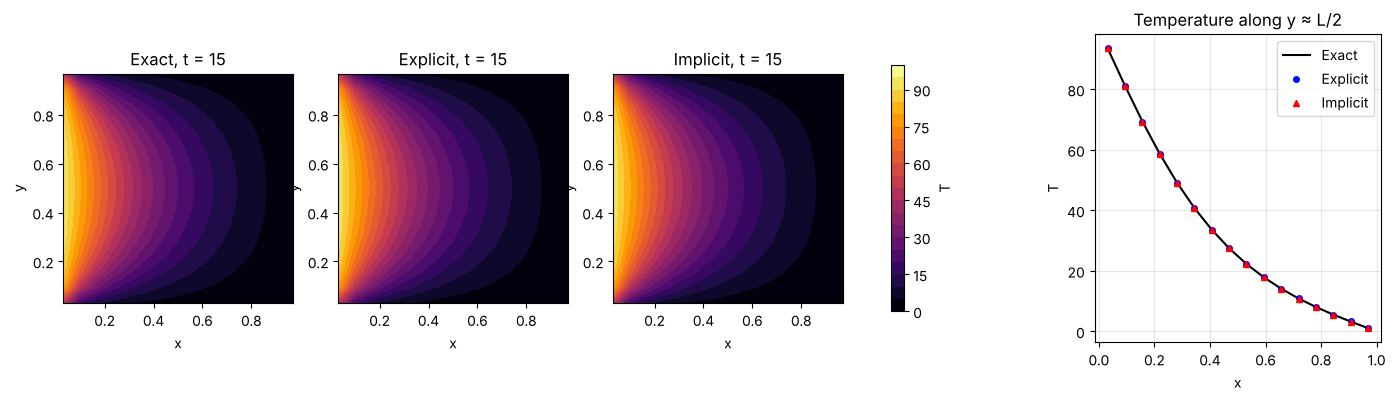

In [ ]:
N = 16
dx = L/N
dt_e = 0.2*dx**2/alpha
dt_i = 0.5
T_e, Fo_e, n_e = solve(N, dt_e, 'explicit')
T_i, Fo_i, n_i = solve(N, dt_i, 'implicit')
T_ex, T_ss = exact(N, t_end)

print(f"Explicit: dt = {dt_e:.4f}, Fo = {Fo_e:.2f}, steps = {n_e}, RMS error = {error(T_e,T_ex)[0]:.3f}, max error = {error(T_e,T_ex)[1]:.3f}")
print(f"Implicit: dt = {dt_i:.4f}, Fo = {Fo_i:.2f}, steps = {n_i}, RMS error = {error(T_i,T_ex)[0]:.3f}, max error = {error(T_i,T_ex)[1]:.3f}")

xc = (np.arange(N)+0.5)*dx
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
levels = np.linspace(0, 100, 21)
for a, F, ttl in zip(ax[:3], (T_ex, T_e, T_i), ('Exact', 'Explicit', 'Implicit')):
    c = a.contourf(xc, xc, F.T, levels=levels, cmap='inferno')
    a.set(title=f'{ttl}, t = {t_end:g}', xlabel='x', ylabel='y', aspect='equal')
fig.colorbar(c, ax=ax[:3], shrink=0.8, label='T')
j = N//2
ax[3].plot(xc, T_ex[:, j], 'k-', label='Exact')
ax[3].plot(xc, T_e[:, j], 'bo', ms=4, label='Explicit')
ax[3].plot(xc, T_i[:, j], 'r^', ms=4, label='Implicit')
ax[3].set(xlabel='x', ylabel='T', title='Temperature along y ≈ L/2'); ax[3].legend(); ax[3].grid(alpha=0.3)
plt.show()

## 5. Effect of grid size (explicit, Fo = 0.2 fixed; implicit with Δt = 0.5)

In [ ]:
rows = []
for Nc in (8, 16, 32):
    dxc = L/Nc
    dtc = 0.2*dxc**2/alpha
    Te, _, ne = solve(Nc, dtc, 'explicit')
    Ti, Foi, _ = solve(Nc, 0.5, 'implicit')
    Tx, _ = exact(Nc, t_end)
    rows.append([Nc, dtc, ne, error(Te, Tx)[0], 0.5, Foi, error(Ti, Tx)[0]])
pd.DataFrame(rows, columns=['N', 'dt (explicit)', 'steps', 'explicit RMS error', 'dt (implicit)', 'Fo (implicit)', 'implicit RMS error'])

,N,dt (explicit),steps,explicit RMS error,dt (implicit),Fo (implicit),implicit RMS error
0,8,0.156250,96,0.627810,0.5,0.64,0.629362
1,16,0.039062,384,0.312984,0.5,2.56,0.315359
2,32,0.009766,1536,0.156517,0.5,10.24,0.160891


## 6. Effect of time step (N = 16) and stability limit

In [ ]:
rows = []
Tx, _ = exact(16, t_end)
for dt in (0.05, 0.2, 0.5, 1.0, 2.5, 5.0):
    Ti, Foi, _ = solve(16, dt, 'implicit')
    rows.append([dt, Foi, error(Ti, Tx)[0], error(Ti, Tx)[1]])
pd.DataFrame(rows, columns=['dt', 'Fo', 'implicit RMS error', 'implicit max error'])

,dt,Fo,implicit RMS error,implicit max error
0,0.05,0.256,0.313014,2.194673
1,0.20,1.024,0.313340,2.195269
2,0.50,2.560,0.315359,2.196623
3,1.00,5.120,0.324583,2.199366
4,2.50,12.800,0.420309,2.211490
5,5.00,25.600,0.796139,2.248021


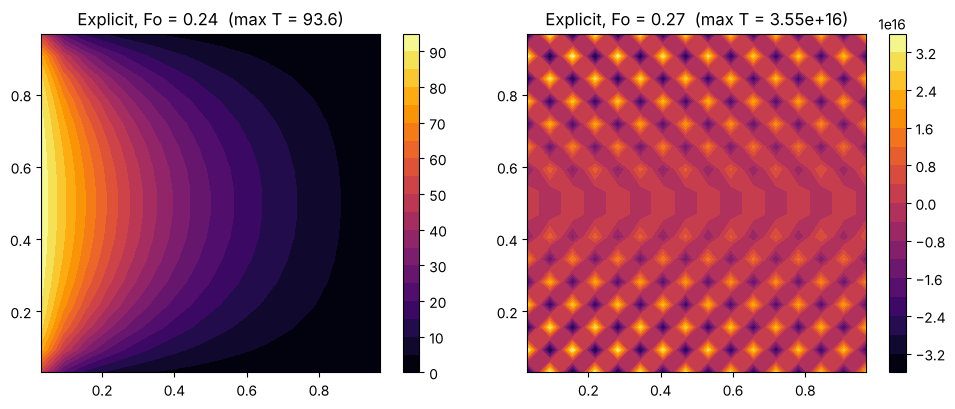

In [ ]:
# Explicit stability limit in 2D is Fo = 0.25
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, Fo in zip(ax, (0.24, 0.27)):
    dt = Fo*dx**2/alpha
    Tu, _, _ = solve(16, dt, 'explicit')
    c = a.contourf(xc, xc, Tu.T, 20, cmap='inferno')
    a.set(title=f'Explicit, Fo = {Fo}  (max T = {Tu.max():.3g})', aspect='equal'); fig.colorbar(c, ax=a)
plt.tight_layout(); plt.show()